In [3]:
import pandas as pd
import geopandas as gpd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.patches as mpatches



# switch the LDC to Foursqure

In [21]:
rc = gpd.read_file('output/rc2025_classified_recLondon.gpkg')

In [44]:
# order tiers sensibly
tier_order = [
    "Regional Centre",
    "Major Town Centre",
    "Town Centre",
    "Market Town",
    "District Centre",
    "Local Centre",
    "Small Local Centre",
    "Large Retail Park",
    "Small Retail Park",
    "Large Shopping Centre",
    "Small Shopping Centre"
]

In [ ]:
rc["group_4squareN"] = rc.groupby("group_id")["Total_POI_count"].transform("sum")

,RC_ID,Total_POI_count,H3_cells,Retail,Dining_and_Drinking,Leisure_Travel,Community_Health,category_names,centre_type,LocalAuthorityNM_1,...,tr_retailN,group_id,group_LDC_retailN,group_RGN_rank,group_CTY_rank,group_LAD_rank,group_BUA_rank,Classification,geometry,group_4squareN
0,6028,16,5,7.0,6.0,0.0,3.0,['Chinese Restaurant' 'Grocery Store' 'Bar' 'R...,centre,North East Derbyshire,...,2,6028,2,542.0,134.0,9.0,3.0,Small Local Centre,"MULTIPOLYGON (((440445.739 367018.091, 440420....",16
1,6646,14,11,11.0,2.0,1.0,0.0,['Fish Market' 'Hardware Store' 'Electronics S...,centre,Cornwall,...,10,6646,10,509.0,59.0,59.0,1.0,Small Local Centre,"MULTIPOLYGON (((194309.881 76200.713, 194331.3...",14
2,1193,131,71,86.0,33.0,4.0,8.0,['Chinese Restaurant' 'Arts and Entertainment'...,centre,North East Derbyshire,...,131,1193,131,65.0,14.0,1.0,1.0,Town Centre,"MULTIPOLYGON (((439116.777 363407.888, 439111....",131
3,6029,16,44,11.0,3.0,2.0,0.0,['Discount Store' 'Gym' 'Pet Supplies Store' '...,centre,North East Derbyshire,...,17,6029,17,294.0,77.0,5.0,2.0,Small Local Centre,"MULTIPOLYGON (((439008.418 364010.854, 438983....",16
4,7409,12,4,6.0,3.0,1.0,2.0,['Music Store' 'Indian Restaurant' 'Italian Re...,centre,Chesterfield,...,8,7409,8,422.0,109.0,15.0,15.0,Small Local Centre,"MULTIPOLYGON (((438294.899 371476.62, 438289.9...",12


In [23]:
rc.columns

Index(['RC_ID', 'Total_POI_count', 'H3_cells', 'Retail', 'Dining_and_Drinking',
       'Leisure_Travel', 'Community_Health', 'category_names', 'centre_type',
       'LocalAuthorityNM_1', 'LocalAuthorityNM_2', 'LocalAuthorityNM_3',
       'was_split', 'Original_POI_count', 'Parent_ID', 'unit_counts',
       'anchor_counts', 'anchor_shops', 'LDC_retailN', 'LAD24NM', 'CountyName',
       'RegionName', 'gsscode', 'tr_retailN', 'group_id', 'group_LDC_retailN',
       'group_RGN_rank', 'group_CTY_rank', 'group_LAD_rank', 'group_BUA_rank',
       'Classification', 'geometry', 'group_4squareN'],
      dtype='object')

In [54]:
# corelation and raw statistic
both = rc[rc["group_LDC_retailN"].notna() & rc["group_4squareN"].notna()].copy()

print(both[["group_LDC_retailN", "group_4squareN"]].describe())
print("\nCorrelation:", both["group_LDC_retailN"].corr(both["group_4squareN"]).round(3))

       group_LDC_retailN  group_4squareN
count        9624.000000     9624.000000
mean          114.490752      176.056941
std           803.248060     1538.156155
min             0.000000        1.000000
25%             8.000000       13.000000
50%            17.000000       23.000000
75%            47.250000       56.000000
max         15688.000000    30587.000000

Correlation: 0.997


In [46]:
# ratio of Foursquare count to LDC retail count
both["ratio_4sq_to_ldc"] = both["group_4squareN"] / both["group_LDC_retailN"]

ratio_summary = (
    both.groupby("Classification")["ratio_4sq_to_ldc"]
    .agg(["median", "mean", "std", "count"])
    .reindex(tier_order)
    .round(3)
)
print(ratio_summary)

                       median   mean    std  count
Classification                                    
Regional Centre         1.620  1.655  0.217    104
Major Town Centre       1.168  1.221  0.413    172
Town Centre             1.098  1.157  0.350    251
Market Town             1.082  1.082  0.151    194
District Centre         1.124  1.172  0.260    276
Local Centre            1.084  1.100  0.242    384
Small Local Centre      1.429    inf    NaN   7035
Large Retail Park       0.861  0.884  0.252    339
Small Retail Park       1.043    inf    NaN    822
Large Shopping Centre   1.063  1.106  0.225     41
Small Shopping Centre   0.942  0.964  0.255      6


In [47]:
# What does group_4squareN actually look like at each current LDC threshold?
ldc_thresholds = {
    "major_town_min (500)":   500,
    "town_centre_min (250)":  250,
    "market_town_min (150)":  150,
    "small_local_max (100)":  100,
}

for label, ldc_val in ldc_thresholds.items():
    # rows near this LDC threshold (±20%)
    window = both[
        both["group_LDC_retailN"].between(ldc_val * 0.8, ldc_val * 1.2)
    ]["group_4squareN"]
    print(f"\nLDC ≈ {label}")
    print(f"  4sq median={window.median():.0f}  "
          f"mean={window.mean():.0f}  "
          f"p25={window.quantile(0.25):.0f}  "
          f"p75={window.quantile(0.75):.0f}  "
          f"n={len(window)}")


LDC ≈ major_town_min (500)
  4sq median=539  mean=544  p25=458  p75=603  n=110

LDC ≈ town_centre_min (250)
  4sq median=262  mean=266  p25=224  p75=298  n=290

LDC ≈ market_town_min (150)
  4sq median=161  mean=164  p25=136  p75=188  n=367

LDC ≈ small_local_max (100)
  4sq median=107  mean=108  p25=89  p75=123  n=489


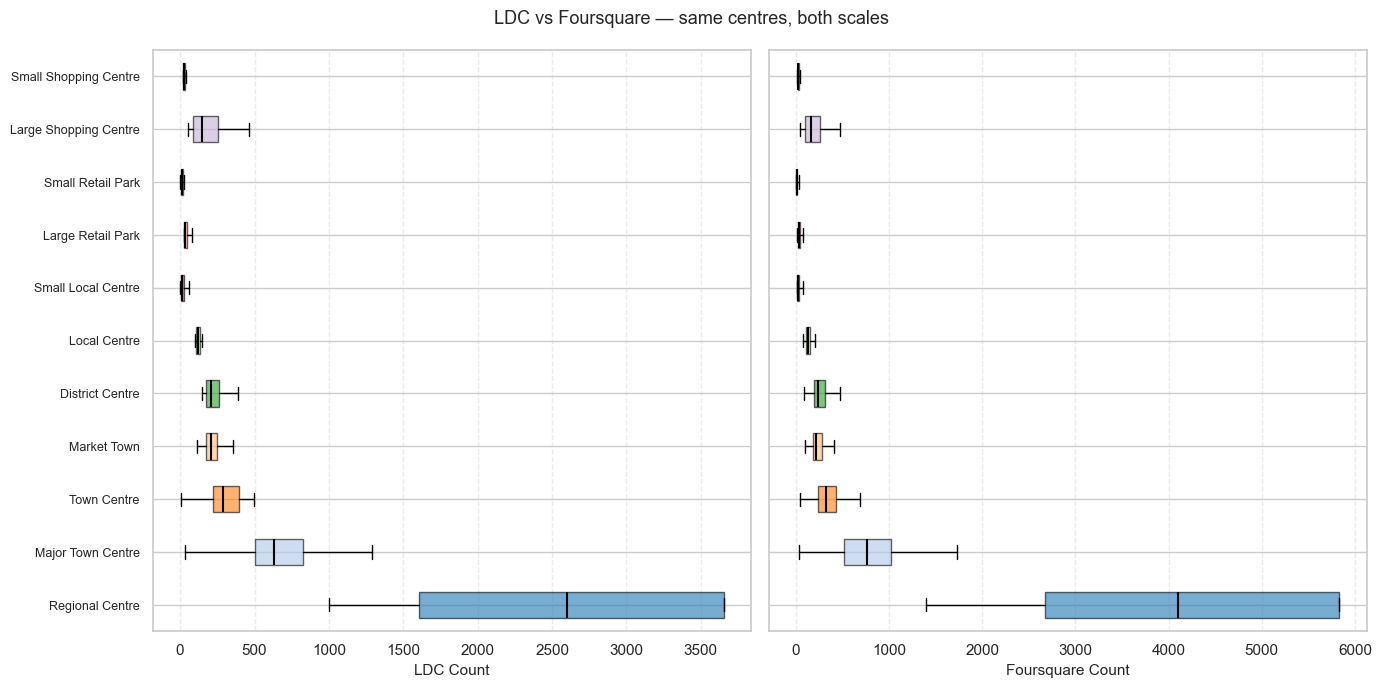

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for ax, col, label in zip(
    axes,
    ["group_LDC_retailN", "group_4squareN"],
    ["LDC Count", "Foursquare Count"]
):
    data = [both.loc[both["Classification"] == t, col].dropna() for t in tier_order]
    bp = ax.boxplot(
        data,
        positions=range(len(tier_order)),
        vert=False, showfliers=False, patch_artist=True,
        medianprops=dict(color="black", linewidth=1.5),
    )

    palette = sns.color_palette("tab20", n_colors=len(tier_order))
    for box, c in zip(bp["boxes"], palette):
        box.set_facecolor(c)
        box.set_alpha(0.6)

    # show class names on y-axis
    ax.set_yticks(range(len(tier_order)))
    ax.set_yticklabels(tier_order, fontsize=9)

    ax.set_xlabel(label, fontsize=11)
    ax.grid(axis="x", linestyle="--", alpha=0.4)

fig.suptitle("LDC vs Foursquare — same centres, both scales", fontsize=13)
plt.tight_layout()
plt.show()


In [52]:
# Median Foursquare count at each tier — use these as your new boundaries
suggested = (
    both.groupby("Classification")["group_4squareN"]
    .median()
    .reindex(tier_order)
    .round(0)
)
print("\nSuggested Foursquare thresholds (median per tier):")
print(suggested)


Suggested Foursquare thresholds (median per tier):
Classification
Regional Centre          4105.0
Major Town Centre         766.0
Town Centre               323.0
Market Town               219.0
District Centre           236.0
Local Centre              129.0
Small Local Centre         20.0
Large Retail Park          33.0
Small Retail Park          11.0
Large Shopping Centre     161.0
Small Shopping Centre      26.0
Name: group_4squareN, dtype: float64


## plots

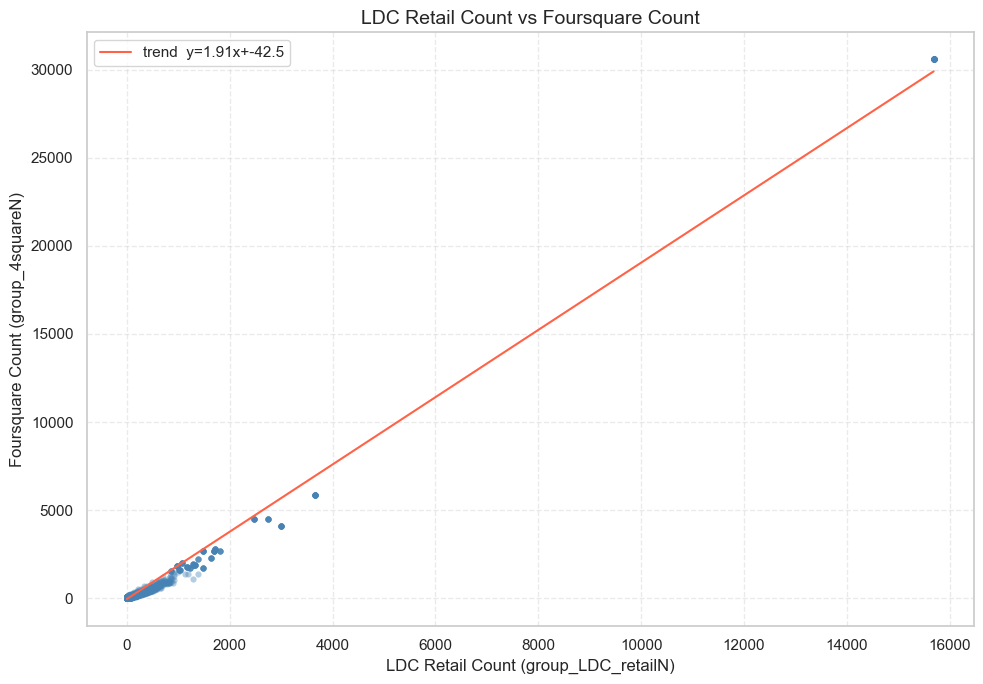

In [ ]:
# raw scatter
fig, ax = plt.subplots(figsize=(10, 7))

# scatter
ax.scatter(
    rc["group_LDC_retailN"],
    rc["group_4squareN"],
    alpha=0.4,
    s=20,
    color="steelblue",
    linewidths=0,
)

# trend line
mask = rc["group_LDC_retailN"].notna() & rc["group_4squareN"].notna()
m, b = np.polyfit(rc.loc[mask, "group_LDC_retailN"], rc.loc[mask, "group_4squareN"], 1)
x_line = np.linspace(rc["group_LDC_retailN"].min(), rc["group_LDC_retailN"].max(), 200)
ax.plot(x_line, m * x_line + b, color="tomato", linewidth=1.5, label=f"trend  y={m:.2f}x+{b:.1f}")

ax.set_xlabel("LDC Retail Count (group_LDC_retailN)", fontsize=12)
ax.set_ylabel("Foursquare Count (group_4squareN)", fontsize=12)
ax.set_title("LDC Retail Count vs Foursquare Count", fontsize=14)
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

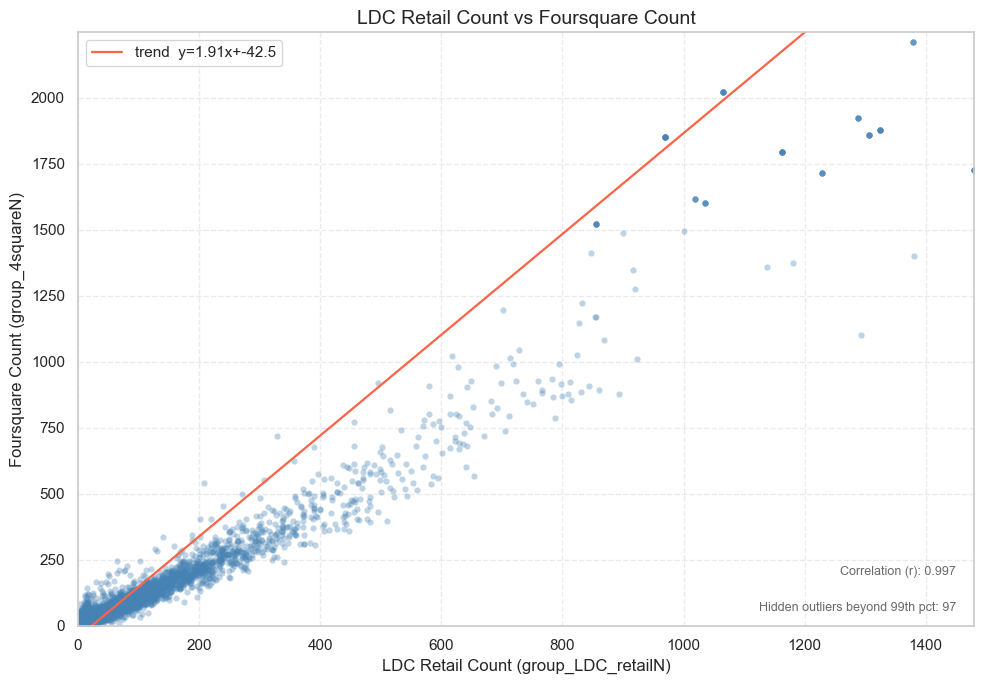

In [55]:
x = rc["group_LDC_retailN"]
y = rc["group_4squareN"]
mask = x.notna() & y.notna()

xv = x[mask].to_numpy()
yv = y[mask].to_numpy()

fig, ax = plt.subplots(figsize=(10, 7))

# all points
ax.scatter(xv, yv, alpha=0.35, s=20, color="steelblue", linewidths=0)

# trend line on full data
m, b = np.polyfit(xv, yv, 1)
x_line = np.linspace(xv.min(), xv.max(), 200)
ax.plot(x_line, m * x_line + b, color="tomato", linewidth=1.6, label=f"trend  y={m:.2f}x+{b:.1f}")

# show main cloud by limiting axis to high percentile
x_hi = np.percentile(xv, 99)
y_hi = np.percentile(yv, 99)
ax.set_xlim(0, x_hi)
ax.set_ylim(0, y_hi)

# optional: annotate hidden outliers count
n_out = ((xv > x_hi) | (yv > y_hi)).sum()
ax.text(
    0.98, 0.02,
    f"Hidden outliers beyond 99th pct: {n_out}",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color="dimgray"
)

# correlation annotation
corr = np.corrcoef(xv, yv)[0, 1]
ax.text(
    0.98, 0.08,
    f"Correlation (r): {corr:.3f}",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color="dimgray"
)

ax.set_xlabel("LDC Retail Count (group_LDC_retailN)", fontsize=12)
ax.set_ylabel("Foursquare Count (group_4squareN)", fontsize=12)
ax.set_title("LDC Retail Count vs Foursquare Count", fontsize=14)
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


/var/folders/55/fvwvclfd7t161kfvx0y7f0hm0000gn/T/ipykernel_42682/4009619310.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/55/fvwvclfd7t161kfvx0y7f0hm0000gn/T/ipykernel_42682/4009619310.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


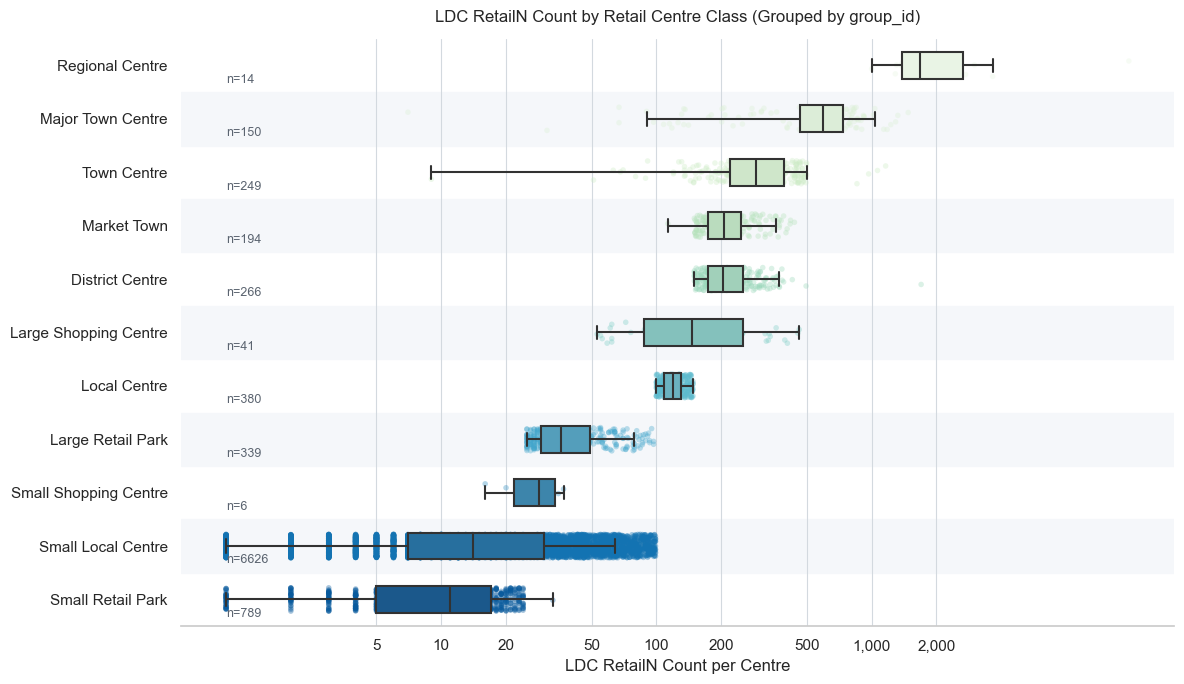

In [56]:
# ldc count per retail centre

# Use rc if present, otherwise fall back to classification
source_df = rc if 'rc' in globals() else classification

# Choose class column name
class_col = 'Classification' if 'Classification' in source_df.columns else 'classification'

# 1) Build group_ldc by summing LDC_retailN per group_id
group_ldc = (
    source_df.groupby('group_id', as_index=False)
    .agg(
        LDC_retailN=('LDC_retailN', 'sum'),
        RC_Class=(class_col, 'first')
    )
)

# Keep only positive values for log scale
plot_df = group_ldc[group_ldc['LDC_retailN'] > 0].copy()

# Order classes by median LDC count (highest first)
order = (
    plot_df.groupby('RC_Class')['LDC_retailN']
    .median()
    .sort_values(ascending=False)
    .index
)

# Color palette per class
palette = sns.color_palette('GnBu', n_colors=len(order))
palette_map = dict(zip(order, palette))

sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(12, 7))

# Alternate row bands
for i, _ in enumerate(order):
    if i % 2 == 1:
        ax.axhspan(i - 0.5, i + 0.5, color='#f5f7fa', zorder=0)

sns.boxplot(
    data=plot_df,
    y='RC_Class',
    x='LDC_retailN',
    order=order,
    orient='h',
    palette=palette_map,
    width=0.5,
    linewidth=1.5,
    showfliers=False,
    zorder=3,
    ax=ax
)

sns.stripplot(
    data=plot_df,
    y='RC_Class',
    x='LDC_retailN',
    order=order,
    orient='h',
    palette=palette_map,
    alpha=0.35,
    size=4,
    jitter=0.22,
    linewidth=0,
    zorder=2,
    ax=ax
)

# Log scale but readable tick labels
ax.set_xscale('log')
ticks = [5, 10, 20, 50, 100, 200, 500, 1000, 2000]
ax.set_xticks(ticks)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}" if x >= 1 else f"{x:g}"))

ax.set_xlabel('LDC RetailN Count per Centre')
ax.set_ylabel('')
ax.set_title('LDC RetailN Count by Retail Centre Class (Grouped by group_id)', pad=12)

# n labels
counts = plot_df.groupby('RC_Class').size().reindex(order)
x_min = plot_df['LDC_retailN'].min()
for i, cls in enumerate(order):
    ax.text(
        x_min, i + 0.27, f'n={counts.loc[cls]}',
        fontsize=9, color='#5b6470', ha='left', va='center'
    )

ax.grid(axis='x', color='#d3d9df', linewidth=0.8)
ax.grid(axis='y', visible=False)
sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

/var/folders/55/fvwvclfd7t161kfvx0y7f0hm0000gn/T/ipykernel_42682/2979127400.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/55/fvwvclfd7t161kfvx0y7f0hm0000gn/T/ipykernel_42682/2979127400.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


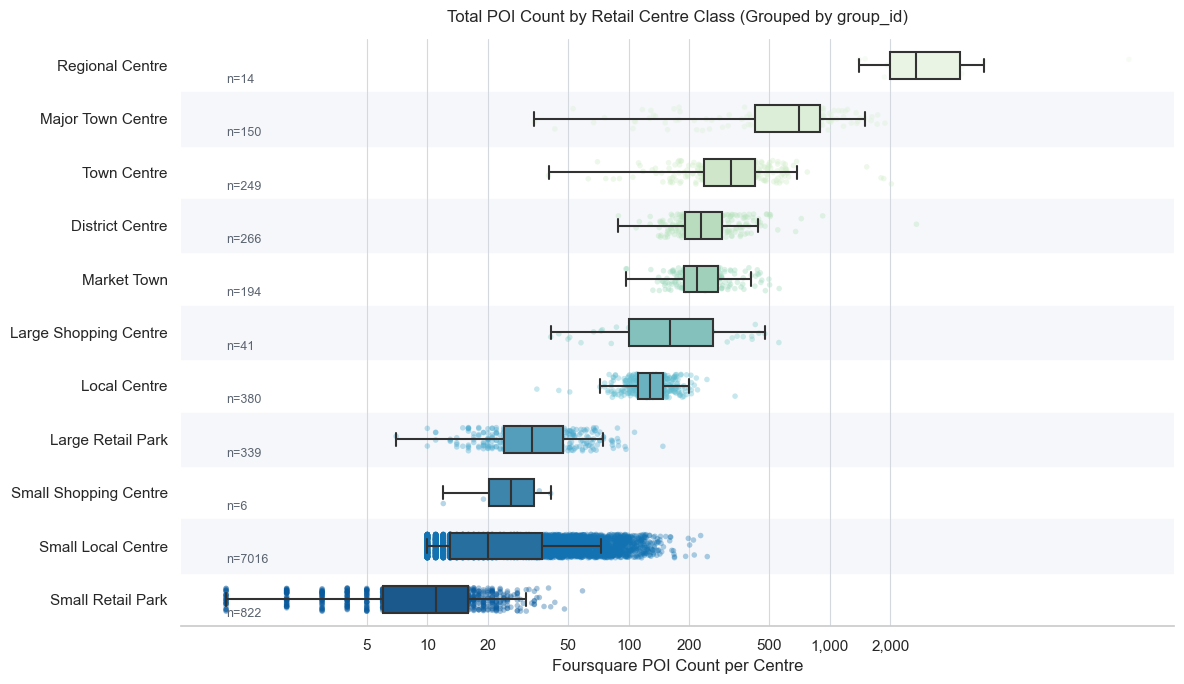

In [57]:
# foursquare count per retail centre

# Choose class column name
class_col = 'Classification' if 'Classification' in source_df.columns else 'classification'

# 1) Build group_4square by summing Total_POI_count per group_id
group_4square = (
    source_df.groupby('group_id', as_index=False)
    .agg(
        Total_POI_count=('Total_POI_count', 'sum'),
        RC_Class=(class_col, 'first')
    )
)

# Keep only positive values for log scale
plot_df = group_4square[group_4square['Total_POI_count'] > 0].copy()

# Order classes by median POI count (highest first)
order = (
    plot_df.groupby('RC_Class')['Total_POI_count']
    .median()
    .sort_values(ascending=False)
    .index
)

# Color palette per class
palette = sns.color_palette('GnBu', n_colors=len(order))
palette_map = dict(zip(order, palette))

sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(12, 7))

# Alternate row bands
for i, _ in enumerate(order):
    if i % 2 == 1:
        ax.axhspan(i - 0.5, i + 0.5, color='#f5f7fa', zorder=0)

sns.boxplot(
    data=plot_df,
    y='RC_Class',
    x='Total_POI_count',
    order=order,
    orient='h',
    palette=palette_map,
    width=0.5,
    linewidth=1.5,
    showfliers=False,
    zorder=3,
    ax=ax
)

sns.stripplot(
    data=plot_df,
    y='RC_Class',
    x='Total_POI_count',
    order=order,
    orient='h',
    palette=palette_map,
    alpha=0.35,
    size=4,
    jitter=0.22,
    linewidth=0,
    zorder=2,
    ax=ax
)

# Log scale but readable tick labels
ax.set_xscale('log')
ticks = [5, 10, 20, 50, 100, 200, 500, 1000, 2000]
ax.set_xticks(ticks)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}" if x >= 1 else f"{x:g}"))

ax.set_xlabel('Foursquare POI Count per Centre')
ax.set_ylabel('')
ax.set_title('Total POI Count by Retail Centre Class (Grouped by group_id)', pad=12)

#n labels
counts = plot_df.groupby('RC_Class').size().reindex(order)
x_min = plot_df['Total_POI_count'].min()
for i, cls in enumerate(order):
    ax.text(
        x_min, i + 0.27, f'n={counts.loc[cls]}',
        fontsize=9, color='#5b6470', ha='left', va='center'
    )

ax.grid(axis='x', color='#d3d9df', linewidth=0.8)
ax.grid(axis='y', visible=False)
sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()



In [39]:
print("groups in classification:",group_ldc["group_id"].nunique())
print("groups in group_4square:", group_4square["group_id"].nunique())

print("groups kept for plot:", plot_df["group_id"].nunique())
print(plot_df.groupby("RC_Class").size())


groups in classification: 9477
groups in group_4square: 9477
groups kept for plot: 9477
RC_Class
District Centre           266
Large Retail Park         339
Large Shopping Centre      41
Local Centre              380
Major Town Centre         150
Market Town               194
Regional Centre            14
Small Local Centre       7016
Small Retail Park         822
Small Shopping Centre       6
Town Centre               249
dtype: int64


In [35]:
group_4square

,group_id,Total_POI_count,RC_Class
0,10,1411,Major Town Centre
1,100,743,Major Town Centre
2,1000,160,Town Centre
3,1001,160,Local Centre
4,1002,160,Local Centre
...,...,...,...
9472,P_5.0,4105,Regional Centre
9473,P_6.0,2767,Regional Centre
9474,P_7.0,2706,Regional Centre
9475,P_8.0,2691,District Centre


# Compare different verison

In [25]:
new_rc_def1 = gpd.read_file('output/rc2025_classified_joined_BUA11_DefUpdated_1.gpkg')
new_rc_def1.value_counts("Classification")

Classification
Small Local Centre       7023
Small Retail Park        1077
Local Centre              390
District Centre           326
Major Town Centre         243
Market Town               187
Town Centre               144
Regional Centre           103
Large Retail Park          83
Large Shopping Centre      40
Small Shopping Centre       6
Name: count, dtype: int64

In [1]:
import geopandas as gpd
import pandas as pd

# load with geometry
a = gpd.read_file("output/rc2025_foursquare_ungroupLondon.gpkg")[["RC_ID", "Classification", "geometry"]]
b = gpd.read_file("output/rc2025_foursquare_LondonMannual.gpkg")[["RC_ID", "Classification", "geometry"]]

a = a.rename(columns={"RC_ID": "RC_ID_a", "Classification": "Classification_a"})
b = b.rename(columns={"RC_ID": "RC_ID_b", "Classification": "Classification_b"})

# ensure same CRS
if a.crs != b.crs:
    b = b.to_crs(a.crs)

# spatial join (intersections)
sj = gpd.sjoin(a, b, how="left", predicate="intersects")

# optional: keep best match only (largest overlap area) to avoid duplicates
sj["overlap_area"] = sj.apply(
    lambda r: r.geometry.intersection(b.loc[r["index_right"], "geometry"]).area
    if pd.notna(r["index_right"]) else 0,
    axis=1
)
best = sj.sort_values("overlap_area", ascending=False).drop_duplicates(subset=["RC_ID_a"])

# differences: no spatial match OR classification mismatch
diff = best[
    best["index_right"].isna() |
    (best["Classification_a"] != best["Classification_b"])
][["RC_ID_a", "Classification_a", "RC_ID_b", "Classification_b", 'geometry']]

#diff.to_file("output/classification_changes.gpkg", driver="GPKG")


In [4]:
best

,RC_ID_a,Classification_a,geometry,index_right,RC_ID_b,Classification_b,overlap_area
956,229,District Centre,"MULTIPOLYGON (((375866.352 396751.43, 375840.8...",956,230,Large Shopping Centre,1.396047e+06
1056,38,Major Town Centre,"MULTIPOLYGON (((474916.534 260368.376, 474891....",1056,39,Major Town Centre,9.811557e+05
2294,1,Regional Centre,"MULTIPOLYGON (((528502.555 180280.192, 528522....",2294,1,Regional Centre,9.297221e+05
2311,7,Regional Centre,"MULTIPOLYGON (((532193.397 181084.989, 532188....",2311,7,Regional Centre,8.808622e+05
2726,24,Major Town Centre,"MULTIPOLYGON (((599106.177 224913.601, 599086....",2725,24,Major Town Centre,8.296973e+05
...,...,...,...,...,...,...,...
6372,7757,Small Local Centre,"MULTIPOLYGON (((615785.691 315457.83, 615765.7...",6370,7755,Small Local Centre,1.866718e+03
7925,9175,Small Local Centre,"MULTIPOLYGON (((327271.501 669720.509, 327251....",7923,9173,Small Local Centre,1.864448e+03
7796,9168,Small Local Centre,"MULTIPOLYGON (((327553.175 689651.392, 327532....",7794,9166,Small Local Centre,1.858374e+03
1286,6360,Small Local Centre,"MULTIPOLYGON (((490174.485 510322.218, 490154....",1286,6358,Small Local Centre,1.857209e+03


In [52]:
check = gpd.read_file("geo/new_postworkshopcentres05Feb26.gpkg")
check.columns

Index(['RC_ID', 'Total_POI_count', 'H3_cells', 'Retail', 'Dining_and_Drinking',
       'Leisure_Travel', 'Community_Health', 'category_names', 'centre_type',
       'LocalAuthorityNM_1', 'LocalAuthorityNM_2', 'LocalAuthorityNM_3',
       'was_split', 'Original_POI_count', 'Parent_ID', 'geometry'],
      dtype='object')

In [2]:
#Check on changing
# old_df = gpd.read_file("output/rc2025_classified_recLondon.gpkg")
# new_df = gpd.read_file("output/rc2025_ldc_ignoreCounty.gpkg")

# old_df = gpd.read_file("output/rc2025_ldc_ignoreCounty.gpkg")
# new_df = gpd.read_file("output/rc2025_foursquare_ignoreCounty.gpkg")

old_df = gpd.read_file("output/rc2025_foursquare_ungroupLondon.gpkg")
new_df = gpd.read_file("output/rc2025_foursquare_LondonMannual.gpkg")
# 1) Build a before/after table
before = old_df[["RC_ID", "group_id", "Classification", "LDC_retailN", 'RegionName']].rename(
    columns={"Classification": "Classification_before"}
)
# after = new_df[["RC_ID", "Classification","group_tri_retailN"]].rename(
#     columns={"Classification": "Classification_after",
#              "group_tri_retailN": "LDC_retailN"}
# )
after = new_df[["RC_ID", "Classification"]].rename(
    columns={"Classification": "Classification_after"}
)

comp = before.merge(after, on="RC_ID", how="inner")

# 2) Changed rows only
changes = comp[comp["Classification_before"] != comp["Classification_after"]].copy()

# 3) Attach geometry from new_df (if it exists)
if "geometry" in new_df.columns:
    changes = changes.merge(    
        new_df[["RC_ID", "geometry"]],
        on="RC_ID",
        how="left"
    )
    changes = gpd.GeoDataFrame(changes, geometry="geometry", crs=new_df.crs)

# 4) Write to GeoPackage
changes["LDC_retailN"] = pd.to_numeric(changes["LDC_retailN"], errors="raise").astype(int)
#changes.to_file("output/classification_changes.gpkg", driver="GPKG")

In [3]:
changes

,RC_ID,group_id,Classification_before,LDC_retailN,RegionName,Classification_after,geometry
0,131,131,Major Town Centre,515,London,Town Centre,"MULTIPOLYGON (((551035.028 188811.465, 551055...."
1,172,172,Major Town Centre,471,London,Town Centre,"MULTIPOLYGON (((525522.106 164093.912, 525542...."
2,12,12,Major Town Centre,1181,London,Town Centre,"MULTIPOLYGON (((531970.433 165631.8, 531945.07..."
3,124,124,Major Town Centre,499,London,Town Centre,"MULTIPOLYGON (((534186.214 176119.708, 534206...."
4,115,115,Major Town Centre,558,London,Town Centre,"MULTIPOLYGON (((540166.658 169161.235, 540186...."
5,35,35,Major Town Centre,824,London,Town Centre,"MULTIPOLYGON (((527124.865 175299.776, 527119...."
6,81,81,Major Town Centre,625,London,Town Centre,"MULTIPOLYGON (((530362.897 175018.758, 530337...."
7,76,76,Major Town Centre,516,London,Town Centre,"MULTIPOLYGON (((517805.88 174563.598, 517780.4..."
8,145,145,Major Town Centre,498,London,Town Centre,"MULTIPOLYGON (((513110.414 175403.919, 513085...."
9,41,41,Major Town Centre,690,London,Town Centre,"MULTIPOLYGON (((517744.102 168977.042, 517718...."


In [4]:
# London metro manual check
import pandas as pd
import geopandas as gpd

metro_points = [
    ("Bromley", 51.4070, 0.0210),
    ("Croydon", 51.3714, -0.1038),
    ("Ealing", 51.5175, -0.2988),
    ("Shepherds Bush", 51.5042, -0.2307),
    ("Wood Green", 51.5981, -0.1149),
    ("Harrow", 51.5836, -0.3464),
    ("Romford", 51.5768, 0.1801),
    ("Uxbridge", 51.5404, -0.4778),
    ("Hounslow", 51.4668, -0.3750),
    ("Kingston", 51.4103, -0.2995),
    ("Stratford", 51.5423, -0.0026),
    ("Ilford", 51.5575, 0.0858),
    ("Sutton", 51.3656, -0.1963),
    ("Canary Wharf", 51.5050, -0.0225),
    ("Brent Cross", 51.5768, -0.2183),
    ("Wembley", 51.5528, -0.2979),
    ("Woolwich", 51.4880, 0.0630),
    ("Lewisham", 51.4610, -0.0050),
]

df = pd.DataFrame(metro_points, columns=["centre_name", "lat", "lon"])
df["network_classification"] = "Metropolitan"

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["lon"], df["lat"]),
    crs="EPSG:4326",
)

gdf.to_file(
    "output/london_metropolitan_points.gpkg",
    layer="london_metropolitan_points",
    driver="GPKG",
)


# london town centre tweak

In [5]:
london_town = gpd.read_file("geo/lodnon_town_centre/London_Town_Centres_Boundaries.gpkg")
london_town

,OBJECTID,layerreference,sitereference,sitename,address,uprn,borough,planningauthority,firstaddeddate,lastupdateddate,...,source,extrainfo1,extrainfo2,extrainfo3,missing,st_area_geom_,st_perimeter_geom_,Shape_Length,Shape_Area,geometry
0,1,TCB00000001,None,Barking,None,None,Barking and Dagenham,Barking & Dagenham,None,None,...,None,None,None,None,None,2.590797e+05,2491.522675,2491.522647,2.590797e+05,"MULTIPOLYGON (((544252.348 184415.85, 544248.8..."
1,2,TCB00000002,None,Chadwell Heath,None,None,Barking and Dagenham,Barking & Dagenham,None,None,...,None,None,None,None,None,6.284616e+04,4415.318162,4415.318188,6.284615e+04,"MULTIPOLYGON (((547755.897 187892.695, 547763...."
2,3,TCB00000003,None,Dagenham Heathway,None,None,Barking and Dagenham,Barking & Dagenham,None,None,...,None,None,None,None,None,2.656345e+04,2014.333581,2014.333674,2.656346e+04,"MULTIPOLYGON (((549083.946 184902.55, 549084.0..."
3,4,TCB00000004,None,Green Lane,None,None,Barking and Dagenham,Barking & Dagenham,None,None,...,None,None,None,None,None,3.383847e+04,2618.422018,2618.421545,3.383848e+04,"MULTIPOLYGON (((547339.398 186902.358, 547345...."
4,5,TCB00000005,None,Brent Street,None,None,Barnet,Barnet,None,None,...,None,None,None,None,None,9.259307e+04,2751.984857,2751.985361,9.259307e+04,"MULTIPOLYGON (((522988.683 189381.561, 523003...."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
229,230,TCB00000228,None,Marylebone Road,None,None,Westminster,Westminster,None,None,...,None,None,None,None,None,1.649917e+05,4203.767363,4203.767363,1.649917e+05,"MULTIPOLYGON (((527959.614 181904.569, 527959...."
230,231,TCB00000229,None,Praed Street/ Paddington,None,None,Westminster,Westminster,None,None,...,None,None,None,None,None,4.315365e+04,5027.109240,5027.109240,4.315365e+04,"MULTIPOLYGON (((526708.3 181050.95, 526706.173..."
231,232,TCB00000230,None,Queensway/ Westbourne Grove,None,None,Westminster,Westminster,None,None,...,None,None,None,None,None,7.876331e+04,7190.518013,7190.517995,7.876331e+04,"MULTIPOLYGON (((524878.953 181044.195, 524881...."
232,233,TCB00000231,None,St John's Wood,None,None,Westminster,Westminster,None,None,...,None,None,None,None,None,1.237175e+04,1868.205027,1868.205206,1.237175e+04,"MULTIPOLYGON (((527113.146 183089.101, 527113...."


In [9]:
london_town['sitename'].startwith("brent")

AttributeError: 'Series' object has no attribute 'startwith'

In [ ]:
import re
import pandas as pd

metro_names = [
    "Bromley",
    "Croydon",
    "Ealing",
    "Shepherds Bush",
    "Wood Green",
    "Harrow",
    "Romford",
    "Uxbridge",
    "Hounslow",
    "Kingston",
    "Stratford",
    "Ilford",
    "Sutton",
    "Canary Wharf",
    "Brent Cross",
    "Wembley",
    "Woolwich",
    "Lewisham",
]

alias_map = {
    "shepherd s bush": "shepherds bush town centre",
    "kingston upon thames": "kingston",
    "canary wharf and docklands": "canary wharf",
}

def norm_name(x):
    if pd.isna(x):
        return ""
    x = str(x).strip().lower()
    x = x.replace("&", "and")
    x = re.sub(r"[^\w\s]", " ", x)
    x = re.sub(r"\s+", " ", x).strip()
    return alias_map.get(x, x)

london_tc_gdf = gpd.read_file("geo/lodnon_town_centre/London_Town_Centres_Boundaries.gpkg")

london_tc_gdf = london_tc_gdf.copy()
london_tc_gdf["sitename_norm"] = london_tc_gdf["sitename"].apply(norm_name)

metro_df = pd.DataFrame({"metro_name": metro_names})
metro_df["metro_name_norm"] = metro_df["metro_name"].apply(norm_name)

available_names = set(london_tc_gdf["sitename_norm"].dropna())

metro_df["found_in_boundary_file"] = metro_df["metro_name_norm"].isin(available_names)

display(
    metro_df.sort_values(["found_in_boundary_file", "metro_name"], ascending=[False, True])
)


,metro_name,metro_name_norm,found_in_boundary_file
0,Bromley,bromley,True
13,Canary Wharf,canary wharf,True
1,Croydon,croydon,True
2,Ealing,ealing,True
5,Harrow,harrow,True
8,Hounslow,hounslow,True
11,Ilford,ilford,True
9,Kingston,kingston,True
17,Lewisham,lewisham,True
6,Romford,romford,True


In [10]:
import difflib

missing = ["brent cross", "shepherds bush"]

all_names = sorted(london_tc_gdf["sitename_norm"].dropna().unique())

for target in missing:
    print(f"\n=== {target} ===")
    
    # close fuzzy matches
    close = difflib.get_close_matches(target, all_names, n=10, cutoff=0.4)
    print("Close matches:", close)
    
    # token-based contains search
    tokens = target.split()
    mask = False
    for token in tokens:
        token_mask = london_tc_gdf["sitename_norm"].str.contains(token, na=False)
        mask = token_mask if isinstance(mask, bool) else (mask | token_mask)
    
    print("\nToken matches:")
    display(
        london_tc_gdf.loc[mask, ["sitename", "sitename_norm"]]
        .drop_duplicates()
        .sort_values("sitename_norm")
        .head(30)
    )



=== brent cross ===
Close matches: ['brompton cross', 'kings cross', 'brent street', 'brentford', 'preston road', 'burnt oak broadway', 'kenton', 'marylebone road', 'green lanes', 'ealing road']

Token matches:


,sitename,sitename_norm
4,Brent Street,brent street
126,Brentford,brentford
138,Brompton Cross,brompton cross
55,King's Cross/ St Pancras,king s cross st pancras
56,Kings Cross,kings cross
169,New Cross and New Cross Gate,new cross and new cross gate



=== shepherds bush ===
Close matches: ['shepherds bush town centre', 'shoreditch', 'herne hill', 'harold hill', 'bakers arms']

Token matches:


,sitename,sitename_norm
97,Shepherds Bush Town Centre,shepherds bush town centre


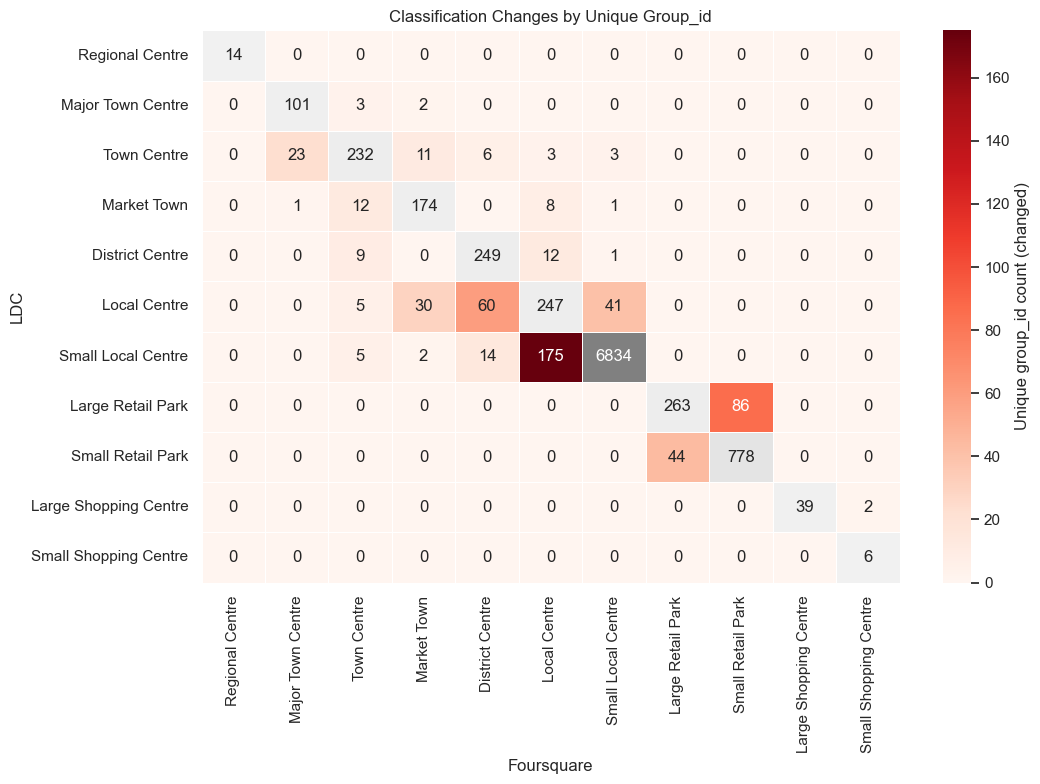

In [142]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

tier_order = [
    "Regional Centre",
    "Major Town Centre",
    "Town Centre",
    "Market Town",
    "District Centre",
    "Local Centre",
    "Small Local Centre",
    "Large Retail Park",
    "Small Retail Park",
    "Large Shopping Centre",
    "Small Shopping Centre",
]

df = comp.dropna(subset=["Classification_before", "Classification_after", "group_id"]).copy()

# unique group_id transitions (NOT row counts)
mat = (
    df.groupby(["Classification_before", "Classification_after"])["group_id"]
      .nunique()
      .unstack(fill_value=0)
      .reindex(index=tier_order, columns=tier_order, fill_value=0)
)

diag_mask = np.eye(len(mat), dtype=bool)

plt.figure(figsize=(11, 8))

# diagonal (unchanged) in gray
sns.heatmap(
    mat.where(diag_mask),
    annot=True,
    fmt=".0f",
    cmap=sns.light_palette("gray", as_cmap=True),
    vmin=0,
    vmax=max(1, int(np.diag(mat).max())),
    cbar=False,
    linewidths=0.5,
    linecolor="white"
)

# off-diagonal (changed) in red
ax = sns.heatmap(
    mat.where(~diag_mask),
    annot=True,
    fmt=".0f",
    cmap="Reds",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Unique group_id count (changed)"}
)

ax.set_xlabel("Foursquare")
ax.set_ylabel("LDC")
ax.set_title("Classification Changes by Unique Group_id")
plt.tight_layout()
plt.show()


In [82]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

tier_order = [
    "Regional Centre",
    "Major Town Centre",
    "Town Centre",
    "Market Town",
    "District Centre",
    "Local Centre",
    "Small Local Centre",
    "Large Retail Park",
    "Small Retail Park",
    "Large Shopping Centre",
    "Small Shopping Centre",
]

df = comp.dropna(subset=["Classification_before", "Classification_after"]).copy()
df = df[
    df["Classification_before"].isin(tier_order) &
    df["Classification_after"].isin(tier_order)
].copy()

flows = (
    df.groupby(["Classification_before", "Classification_after"], as_index=False)
      .size()
      .rename(columns={"size": "count"})
)

show_unchanged = True
if not show_unchanged:
    flows = flows[flows["Classification_before"] != flows["Classification_after"]].copy()

# ---- FIX 1: compress very large flows so nodes/links don't overlap visually ----
flows["plot_value"] = np.sqrt(flows["count"])   # use for Sankey width
# flows["plot_value"] = np.log1p(flows["count"])  # alternative

left_nodes = tier_order[:]
right_nodes = tier_order[:]
n = len(tier_order)
labels = left_nodes + right_nodes

left_map = {c: i for i, c in enumerate(left_nodes)}
right_map = {c: i + n for i, c in enumerate(right_nodes)}

source = flows["Classification_before"].map(left_map).tolist()
target = flows["Classification_after"].map(right_map).tolist()
value = flows["plot_value"].tolist()  # scaled values for drawing

def y_positions(n):
    if n == 1:
        return [0.5]
    step = 1 / (n + 1)
    return [step * (i + 1) for i in range(n)]

node_x = [0.01] * n + [0.99] * n
node_y = y_positions(n) + y_positions(n)

link_colors = [
    "rgba(120,120,120,0.20)" if b == a else "rgba(31,119,180,0.45)"
    for b, a in zip(flows["Classification_before"], flows["Classification_after"])
]

fig = go.Figure(
    go.Sankey(
        arrangement="fixed",
        node=dict(
            label=labels,
            x=node_x,
            y=node_y,
            pad=22,          # ---- FIX 2: bigger gap between categories ----
            thickness=10,    # thinner nodes helps spacing
            line=dict(color="rgba(0,0,0,0.35)", width=0.4),
            color=(["#4c78a8"] * n + ["#f58518"] * n),
        ),
        link=dict(
            source=source,
            target=target,
            value=value,
            color=link_colors,
            customdata=flows["count"],  # real counts in hover
            hovertemplate=(
                "From: %{source.label}<br>"
                "To: %{target.label}<br>"
                "n=%{customdata}<extra></extra>"
            ),
        ),
    )
)

fig.update_layout(
    title="Classification Flow (Same Tier Order Left and Right)",
    width=1400,
    height=1200,   # ---- FIX 3: more vertical room ----
    font_size=11
)

fig.show()


In [8]:
import pandas as pd
import geopandas as gpd
from pathlib import Path

outlets = pd.DataFrame(
    [
        ("Regional Shopping Centre", "Westfield London", 51.50768597440922, -0.22088352838801395),
        ("Regional Shopping Centre", "Metrocentre", 54.957214904105754, -1.6674536751658506),
        ("Regional Shopping Centre", "Trafford Centre", 53.465100417291744, -2.347637851106119),
        ("Regional Shopping Centre", "Westfield Stratford City", 51.54425552636472, -0.004332458383472109),
        ("Regional Shopping Centre", "Bluewater", 51.43912203176112, 0.27160383738290644),
        ("Regional Shopping Centre", "intu Merry Hill", 52.48138718476229, -2.110658395511001),
        ("Regional Shopping Centre", "Lakeside Shopping Centre", 51.489406902239956, 0.2853764470235825),
        ("Regional Shopping Centre", "Meadowhall", 53.41411230589209, -1.4111151687565566),
        ("Regional Shopping Centre", "East Kilbride Shopping Centre", 55.76021412051323, -4.17708950101207),
        ("Regional Shopping Centre", "Silverburn Centre", 55.82112954772368, -4.341253330960348),
        ("Regional Shopping Centre", "intu Braehead", 55.87600450967236, -4.364642953985305),
        ("Regional Shopping Centre", "White Rose Centre", 53.75868081616114, -1.5734907774777223),
        ("Large Outlet Shopping Centre", "Ashford Designer Outlet", 51.137387301260496, 0.8801687441992894),
        ("Large Outlet Shopping Centre", "Astle Park West Bromwich", 52.520103339621166, -1.9960259925402608),
        ("Large Outlet Shopping Centre", "Bicester Outlet Village", 51.89237714202758, -1.1560770883204268),
        ("Large Outlet Shopping Centre", "Bideford Atlantic Village", 51.00755545946937, -4.237327761297502),
        ("Large Outlet Shopping Centre", "Castleford Junction 32 Outlet", 53.712463797168354, -1.3388364244282458),
        ("Large Outlet Shopping Centre", "Chatham Dockside Outlet Centre", 51.40160304040388, 0.5377104489852201),
        ("Large Outlet Shopping Centre", "Cheshire Oaks Designer Outlet", 53.26539272808919, -2.8809029974792315),
        ("Large Outlet Shopping Centre", "Clacton Factory Outlet", 51.81858769266023, 1.168209463308007),
        ("Large Outlet Shopping Centre", "Clarks Village Outlet Somerset", 51.12833201493458, -2.741588552823589),
        ("Large Outlet Shopping Centre", "Dalton Park Outlet", 54.81537131857434, -1.3739226162513756),
        ("Large Outlet Shopping Centre", "Doncaster Lakeside Village", 53.50769203205623, -1.1135984485990036),
        ("Large Outlet Shopping Centre", "Dover De Bradelei Wharf Outlet", 51.12211019226935, 1.3141697547138849),
        ("Large Outlet Shopping Centre", "East Midlands Outlet Junction 28", 53.108083884731556, -1.3126583496100666),
        ("Large Outlet Shopping Centre", "Freeport Braintree", 51.870070700810075, 0.5714801267433955),
        ("Large Outlet Shopping Centre", "Freeport Fleetwood Outlet", 53.91786152727727, -3.0118505404061744),
        ("Large Outlet Shopping Centre", "Freeport Talke Stoke-on-Trent", 53.070597467076176, -2.263078253210015),
        ("Large Outlet Shopping Centre", "Gloucester Quays Outlet", 51.85953205593224, -2.2516156614946916),
        ("Large Outlet Shopping Centre", "Hertfordshire Galleria Outlet Shopping", 51.76141229905345, -0.24021860677316503),
        ("Large Outlet Shopping Centre", "Hornsea Freeport Outlet", 53.898485374967684, -0.1724229262407349),
        ("Large Outlet Shopping Centre", "Kilver Court Designer Village", 51.19063584650441, -2.5353243560244905),
        ("Large Outlet Shopping Centre", "London Designer Outlet Wembley", 51.55646778421662, -0.28320440479433673),
        ("Large Outlet Shopping Centre", "Lowry Outlet Salford Quays", 53.47092253822526, -2.292514874626797),
        ("Large Outlet Shopping Centre", "Newcastle Royal Quays Outlet", 54.99532901611218, -1.4642812945442476),
        ("Large Outlet Shopping Centre", "Portsmouth Gunwharf Quays", 50.79546395254288, -1.103824062300293),
        ("Large Outlet Shopping Centre", "Springfields Spalding Outlet", 52.799438891276665, -0.126329033767297),
        ("Large Outlet Shopping Centre", "Swindon Designer Outlet", 51.56272470333755, -1.7971899666540831),
        ("Large Outlet Shopping Centre", "The Mill Outlet Batley", 53.7129199988173, -1.6251337290018772),
        ("Large Outlet Shopping Centre", "York Designer Outlet", 53.92233415376806, -1.0768705880781113),
        ("Large Outlet Shopping Centre", "Banbridge Village Outlet", 54.33172185692118, -6.276147653115943),
        ("Large Outlet Shopping Centre", "Cribbs Causeway", 51.524552488774034, -2.5955220725284307),
        ("Large Outlet Shopping Centre", "Bridgend Designer Outlets Wales", 51.532410963682594, -3.576839020076668),
        ("Large Outlet Shopping Centre", "Gretna Gateway Outlet Village", 54.99688074646182, -3.056523264134829),
        ("Large Outlet Shopping Centre", "Livingston Designer Outlet", 55.88310933797727, -3.520137944032474),
        ("Large Outlet Shopping Centre", "Sterling Mills Outlet", 56.14927287877639, -3.740053433726151),
    ],
    columns=["SubType", "Name", "Lat", "Lon"],
)

outlets["Type"] = "Out of Town Shopping Centres"

outlets_gdf = gpd.GeoDataFrame(
    outlets,
    geometry=gpd.points_from_xy(outlets["Lon"], outlets["Lat"]),
    crs="EPSG:4326",
)

out_path = Path("output/outlets.gpkg")
out_path.parent.mkdir(parents=True, exist_ok=True)

outlets_gdf.to_file(out_path, layer="outlets", driver="GPKG")
print(f"Saved {len(outlets_gdf)} points to {out_path}")
outlets_gdf.head()



Saved 46 points to output/outlets.gpkg


,SubType,Name,Lat,Lon,Type,geometry
0,Regional Shopping Centre,Westfield London,51.507686,-0.220884,Out of Town Shopping Centres,POINT (-0.22088 51.50769)
1,Regional Shopping Centre,Metrocentre,54.957215,-1.667454,Out of Town Shopping Centres,POINT (-1.66745 54.95721)
2,Regional Shopping Centre,Trafford Centre,53.465100,-2.347638,Out of Town Shopping Centres,POINT (-2.34764 53.4651)
3,Regional Shopping Centre,Westfield Stratford City,51.544256,-0.004332,Out of Town Shopping Centres,POINT (-0.00433 51.54426)
4,Regional Shopping Centre,Bluewater,51.439122,0.271604,Out of Town Shopping Centres,POINT (0.2716 51.43912)
